In [8]:
import sys
print(sys.executable)

C:\Users\PADMAVATHI\toxic-filter\.venv\Scripts\python.exe


In [10]:
from pathlib import Path
print("Working dir:", Path.cwd())
print("Looking in: ", RAW)
print("Exists:     ", RAW.exists())
print("Contents:   ", list(RAW.glob("*")) if RAW.exists() else "folder missing")

Working dir: C:\Users\PADMAVATHI\toxic-filter\notebooks
Looking in:  C:\Users\PADMAVATHI\toxic-filter\data\raw
Exists:      True
Contents:    [WindowsPath('C:/Users/PADMAVATHI/toxic-filter/data/raw/train.csv'), WindowsPath('C:/Users/PADMAVATHI/toxic-filter/data/raw/train.csv.zip')]


In [15]:
path = next(RAW.glob("train.csv*"))

print("Path:", path)
print("Is file:", path.is_file())
print("Is directory:", path.is_dir())

Path: C:\Users\PADMAVATHI\toxic-filter\data\raw\train.csv
Is file: True
Is directory: False


In [17]:
path = next(RAW.glob("train.csv*"))
df = pd.read_csv(path)
print(path, df.shape)
df.head()

C:\Users\PADMAVATHI\toxic-filter\data\raw\train.csv (159571, 8)


,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0


In [18]:
print(list(RAW.glob("*")))

[WindowsPath('C:/Users/PADMAVATHI/toxic-filter/data/raw/train.csv')]


In [19]:
import os, re
import numpy as np, pandas as pd
import seaborn as sns, matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW  = ROOT / "data" / "raw"
OUT  = ROOT / "data" / "processed"
OUT.mkdir(parents=True, exist_ok=True)

LABELS = ["toxic","severe_toxic","obscene","threat","insult","identity_hate"]
SEED = 42

path = next(RAW.glob("train.csv*"))
df = pd.read_csv(path)
print(path, df.shape)   # expect ~159,571 rows
df.head()

C:\Users\PADMAVATHI\toxic-filter\data\raw\train.csv (159571, 8)


,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0


In [20]:
print(df.isna().sum())
print("Exact duplicate texts:", df.comment_text.duplicated().sum())
print("Labels strictly 0/1:", df[LABELS].isin([0,1]).all().all())

id               0
comment_text     0
toxic            0
severe_toxic     0
obscene          0
threat           0
insult           0
identity_hate    0
dtype: int64
Exact duplicate texts: 0
Labels strictly 0/1: True


In [21]:
counts = df[LABELS].sum().to_frame("positives")
counts["pct"] = (counts.positives / len(df) * 100).round(2)
print(counts)

df["any_toxic"] = df[LABELS].max(axis=1)
print("Clean comments:", round((df.any_toxic == 0).mean(), 3))

               positives   pct
toxic              15294  9.58
severe_toxic        1595  1.00
obscene             8449  5.29
threat               478  0.30
insult              7877  4.94
identity_hate       1405  0.88
Clean comments: 0.898


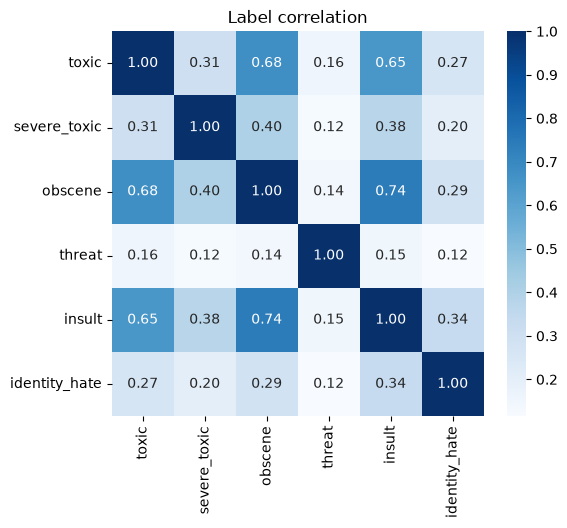

In [22]:
plt.figure(figsize=(6,5))
sns.heatmap(df[LABELS].corr(), annot=True, fmt=".2f", cmap="Blues")
plt.title("Label correlation"); plt.show()

count    159571.000000
mean         67.273527
std          99.230702
min           1.000000
50%          36.000000
90%         152.000000
95%         230.000000
99%         567.000000
max        1411.000000
Name: n_words, dtype: float64


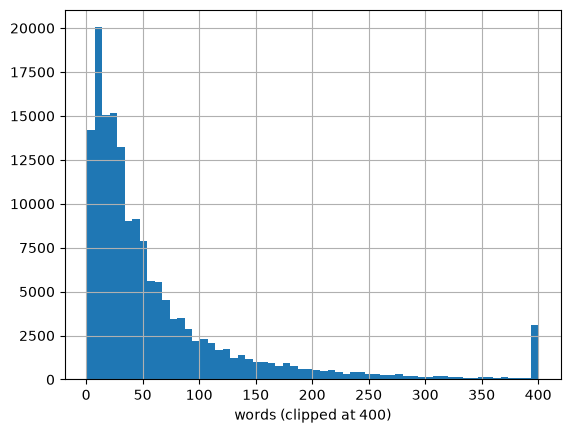

In [24]:
df["n_words"] = df.comment_text.str.split().str.len()
print(df.n_words.describe(percentiles=[.5,.9,.95,.99]))

df.n_words.clip(upper=400).hist(bins=60)
plt.xlabel("words (clipped at 400)"); plt.show()

In [25]:
from transformers import AutoTokenizer
tok = AutoTokenizer.from_pretrained("distilbert-base-uncased")

sample = df.comment_text.sample(20000, random_state=SEED).tolist()
lens = np.array([len(x) for x in tok(sample, add_special_tokens=True)["input_ids"]])
for L in (64, 128, 192, 256):
    print(f"max_length={L}: covers {(lens <= L).mean():.1%}")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (799 > 512). Running this sequence through the model will result in indexing errors


max_length=64: covers 58.8%
max_length=128: covers 81.4%
max_length=192: covers 89.5%
max_length=256: covers 93.5%
